<h1><center>Data Analysis and Simulation</center></h1>
<h3><center>Working notebook</center></h3>

# Imports

In [1]:
# Matplotlib setup, could be swapped for pyqt (realtime) or data shader(large datasets)
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
%config InlineBackend.figure_format = 'retina'

# Dependencies
import astropy.constants as c
from astropy.coordinates import EarthLocation, AltAz, SkyCoord
from astropy.time import Time
import astropy.units as u

import datetime
import glob
import numpy as np
import os
import pandas as pd
from rich.progress import track

from scipy import ndimage
from scipy.optimize import leastsq
from scipy.signal import csd, welch, fftconvolve
from scipy.signal.windows import blackmanharris
from scipy.spatial.distance import pdist


# Parameter Initilization 
Insert correct parameters for the interferometer here

When simulating; simulate_antennas = True

When using real data; simulate_antennas = False


## User defined constants

In [ ]:
# Define key interferometer parameters
CENTRAL_FREQ = 1416.4*u.MHz
N_CHANNELS = 2**11
SAMP_RATE = 10*u.MHz
TARGET_FREQ = 1.420406*u.GHz

#this could be a file. 
# Define antenna positions in local coordinates (x, y, z) in meters
posx = [0.44351937, 0.31049445, 0.49270715, -0.40862047, -0.00241969, -0.33720132, 0.08623691, -0.21437422, -0.37034218]
posy = [0.25675033, -0.36953188, 0.00338735, 0.09358719, 0.52380058, 0.36831369, -0.3100637, -0.22048946, -0.34575411]
posz = [0, 0, 0, 0, 0, 0, 0, 0, 0]
num_antennas = len(posx)

# Observation coordinates and time(s)
LAT = +52.168638*u.deg
LONG = +4.45827*u.deg
ELEV = 30*u.m 
DATE = datetime.date(2026,11,27)
TIME = datetime.time(14,00,00)
READ_ALL_FILES_IN_FOLDER = False

# Target details. this requires the time to be correct
ALT = +26*u.deg
AZ  = +160*u.deg

# Algo control params
SIMULATE_ANTENNAS = True # toggle artificial antennas generation here
REFERENCE_ANTENNA_NUMBER = 1
INT_TIME = 10 * u.min # Integration time for data
SKY_COVERAGE = 2*u.rad

FOLDER_NOMENCLATURE = f'../data/obs/' # DT pattern gets handled automatically
FILE_NOMENCLATURE = 'antenna_*.bin'
META_NOMENCLATURE = 'metadata.json'
POSITION_NOMENCLATURE = 'antenna_pos_leg.csv'

In [3]:
if READ_ALL_FILES_IN_FOLDER == True: 
    if SIMULATE_ANTENNAS == True:
        raise ValueError('We currently don\'t simulate with multiple folders')

## Automated constants

In [4]:
FREQ_RES = (SAMP_RATE/N_CHANNELS).to(u.GHz)
LOWEST_FREQ = (CENTRAL_FREQ - SAMP_RATE/2).to(u.GHz)
SUBBAND = int(np.floor((TARGET_FREQ-LOWEST_FREQ)/FREQ_RES))
assert SUBBAND <= N_CHANNELS, 'The target frequency is outside the number of channels'

CWD = os.getcwd()
DT = 1/SAMP_RATE.to(1/u.s)
OBS_TIME = datetime.datetime.combine(DATE,TIME)
LOCATION=EarthLocation.from_geodetic(LONG,LAT,ELEV)
ALTAZ_COORD = SkyCoord(alt=ALT,az=AZ,frame=AltAz(obstime=OBS_TIME,location=LOCATION))
GAL_COORD = ALTAZ_COORD.transform_to("galactic")
GAL_LAT = GAL_COORD.b
GAL_LONG = GAL_COORD.l
# built for glob not regex
# file convention
DATE_STR = str(DATE).replace('-','')
TIME_STR = str(TIME).replace(':','')
D_PATTERN = rf"{DATE_STR}T??????Z"
DT_PATTERN = rf"{DATE_STR}T{TIME_STR}Z"

# Find the folders for data

In [5]:
def folder_finder(folders):
    if len(folders) == 0:
        return 0
    elif len(folders) == 1:
        return 1
    elif len(folders) > 1 : 
        return 2

def ask_user_folder(folders):
    print('Too many folders discovered, please select which by entering the digit associated')
    for _, folder in enumerate(folders):
        isolate = folder.split('/')[3]
        print(f'{_}, {isolate.split('T')[0]}, {isolate.split('T')[1]}')
    user = input('Which folder will you select?: ')
    DATA_FOLDER = folders[int(user)]
    print(f'Folder discovered, set to {folders[int(user)]}')
    return DATA_FOLDER

In [6]:
if not READ_ALL_FILES_IN_FOLDER:
    folders = glob.glob(os.path.join(FOLDER_NOMENCLATURE,D_PATTERN))

    # 0 means error
    if len(folders) == 0:
        print(f'The date entered is {DATE}')
        print(f'The pattern entered is {FOLDER_NOMENCLATURE}')
        raise ValueError('No folders where detected, one of the following has occured: ' \
                        '\n The folder does not exist ' \
                        '\n The date is incorrect ' \
                        '\n The date on the folder is incorrect ' \
                        '\n The pattern is incorrect ' \
                        '\n CWD must be included in the folder nomenclature')

    # 1 means no other option
    elif len(folders) == 1:
        DATA_FOLDER = folders[0]
        print(f'Folder discovered, set to {folders[0]}')

    # recursive shift through time variable to find folder
    # if too many are found then ask the user 
    elif len(folders) > 1 : 
        try:
            time = ''
            last_good_str = ''
            last_flag = 0
            for value in TIME_STR:
                time += value
                pattern = D_PATTERN.split("?")[0]
                wild = 6-len(time)
                pattern = pattern + time + "?"*wild + 'Z'
                try_folders = glob.glob(os.path.join(FOLDER_NOMENCLATURE,pattern))
                if folder_finder(try_folders) == 2:
                    last_flag = 2
                    last_good_str = pattern
                    continue
                elif folder_finder(try_folders) == 1:
                    DATA_FOLDER = try_folders[0]
                    print(f'Folder discovered, set to {try_folders[0]}')
                    break
                else:
                    if last_flag != 0:
                        DATA_FOLDER = ask_user_folder(try_folders)
                        break
                    else:
                        raise ValueError('Failed the auto finder')
        except:
            DATA_FOLDER = ask_user_folder(folders)
    N_OBS = 1

    obs_times = [Time(OBS_TIME)]

else:
    folders = glob.glob(os.path.join(FOLDER_NOMENCLATURE))
    DATA_FOLDER = folders[0]
    
    obs_folders = glob.glob(os.path.join(FOLDER_NOMENCLATURE,"*"))
    obs_times = [Time(datetime.datetime.fromisoformat(folder.split("/")[-1])) for folder in obs_folders]
    N_OBS = len(glob.glob(os.path.join(FOLDER_NOMENCLATURE,"*")))

Folder discovered, set to ../data/obs/20261127T140000Z


In [7]:
if READ_ALL_FILES_IN_FOLDER:
    antenna_data_files = glob.glob(os.path.join(DATA_FOLDER,"*",FILE_NOMENCLATURE))
    antenna_pos_file = glob.glob(os.path.join(DATA_FOLDER,"*",POSITION_NOMENCLATURE))[0]
    metadata_files = glob.glob(os.path.join(DATA_FOLDER,"*",META_NOMENCLATURE))[0]
else:
    antenna_data_files = glob.glob(os.path.join(DATA_FOLDER,FILE_NOMENCLATURE))
    antenna_pos_file = glob.glob(os.path.join(DATA_FOLDER,POSITION_NOMENCLATURE))[0]
    metadata_files = glob.glob(os.path.join(DATA_FOLDER,META_NOMENCLATURE))[0]

# 1.  Antenna Config 

Coordinate handling functions

In [8]:
#ENU Y is along NS, +Y -> N, +X -> E
def cartesian_to_radial(pos_arr):
    assert isinstance(pos_arr,np.ndarray), 'The position array has to be a numpy array'
    dx = pos_arr[:,0]
    dy = pos_arr[:,1]
    dz = pos_arr[:,2]
    radii= np.sqrt(dx**2 + dy**2 + dz**2) #XYZ
    theta= np.acos(dz/radii) #Zr
    phi  = np.arctan2(dy/dx) #YX

    return np.array([radii,theta,phi]).T

def spherical_enu_to_cartesian(pos_arr): 
    assert isinstance(pos_arr,np.ndarray), 'The position array has to be a numpy array'
    # Assumtion here is that r is in meters and theta/phi are in radians
    # had to change this to follow ENU not mathematical
    r       = pos_arr[:,0]
    theta   = pos_arr[:,1]
    phi     = pos_arr[:,2]
    x = r*np.cos(theta)*np.sin(phi)
    y = r*np.cos(theta)*np.cos(phi)
    z = r*np.sin(theta)

    return np.array([x,y,z]).T

Load antenna positions <br>Check number of antenna data files vs number of positions provided<br>Calculate baseline<br>Everything gets referenced to reference antenna

In [9]:
antenna_positions = pd.read_csv(antenna_pos_file,header=0,index_col=0,dtype=np.float32,skipinitialspace=True)
# Sort antenna 1-9, positions x-z

if antenna_positions.columns.isin(['r','theta','phi']).all():
    antenna_positions = antenna_positions.sort_index()[['r','theta','phi']].to_numpy()
    antenna_positions = antenna_positions-antenna_positions[REFERENCE_ANTENNA_NUMBER-1]
    antenna_positions = spherical_enu_to_cartesian(antenna_positions)*u.m
else:
    assert antenna_positions.columns.isin(['x','y','z']).all(), 'Antenna positions are not in cartesian.' 
    antenna_positions = antenna_positions.sort_index()[['x','y','z']].to_numpy()*u.m
    antenna_positions = antenna_positions-antenna_positions[REFERENCE_ANTENNA_NUMBER-1]

num_antennas = antenna_positions.shape[0]
largest_baseline = np.max(pdist(antenna_positions)) * u.m

if SIMULATE_ANTENNAS:
    assert len(antenna_data_files) == 1, 'We only require 1 data file for simulating the array'
    assert antenna_positions.shape[0] >= 1, 'We require some antenna positions, none were provided'

elif len(antenna_data_files) != antenna_positions.shape[0] :
    raise ValueError('The amount of antenna data files does not match the amount of postions provided')

# only other condition is we are not simulating and the amount of files is equal

Time/phase delay calculation for each antenna

In [10]:
wavelenght = c.c/TARGET_FREQ.to(1/u.s)
normal_vector = np.array([[1,ALT.to_value(u.rad),AZ.to_value(u.rad)]])
normal_vector = spherical_enu_to_cartesian(normal_vector).flatten()

# As we are ENU, alt az are correct angles
# As the arrays are referenced to an antenna, we don't need to insert a position for the antenna as it is 0,0,0

def phase_delay_calc(pos_arr):
    distance = pos_arr @ normal_vector / np.linalg.norm(normal_vector) #the demoninator is redudant if normal is set correctly
    phase_delay = 2*np.pi*distance/wavelenght
    time_delay = phase_delay/TARGET_FREQ.to(1/u.s)
    return phase_delay, time_delay

ant_phase_delays,ant_time_delays = phase_delay_calc(antenna_positions)


In [11]:
# assemble position array and derive important properties
%store antenna_positions
%store largest_baseline
print(f"Array comprised of {num_antennas} antennas with a largest baseline of {largest_baseline:.2f} and data from {N_OBS} distinct times")

Stored 'antenna_positions' (Quantity)
Stored 'largest_baseline' (Quantity)
Array comprised of 9 antennas with a largest baseline of 0.98 m and data from 1 distinct times


### 1.1 compute UV plane

In [12]:
def compute_uv_coordinates(ant_pos, hour_angles, dtype=np.float32):
  
  num_times = len(hour_angles)
  hour_angles_rad = np.radians(hour_angles)

  east = ant_pos[:, 0] #x
  north = ant_pos[:, 1] #y
  el = ant_pos[:, 2] #z

  # ACM 
  dx = east[np.newaxis, :] - east[:, np.newaxis]
  dy = north[np.newaxis, :] - north[:, np.newaxis]
  dz = el[np.newaxis, :] - el[:, np.newaxis]

  result = np.zeros((num_times, num_antennas, num_antennas, 3), dtype=dtype)

  for t_idx, h in enumerate(hour_angles_rad):
    sin_h = np.sin(h)
    cos_h = np.cos(h)
    sin_alt = np.sin(ALT.to(u.rad))
    cos_alt = np.cos(ALT.to(u.rad))

    #trust, seems to work lol 
    uu = sin_h*dx + cos_h*dy
    v = -sin_alt*cos_h*dx + sin_alt*sin_h*dy + cos_alt*dz
    w = cos_alt*cos_h*dx - cos_alt*sin_h*dy + sin_alt*dz

    result[t_idx, :, :, 0] = uu
    result[t_idx, :, :, 1] = v
    result[t_idx, :, :, 2] = w

  idx = np.arange(num_antennas)
  #result[:, idx, idx, :] = np.nan

  return result

### 1.2 UV coverage of Earth rotation during integration time

In [ ]:
#calculate the alt az, galactic and ra dec coordinates of leiden at the observation times

#Assuming stationary pointing and scanning, rather than tracking
altaz_frames = [AltAz(obstime=obs_times[i], location=LOCATION) for i in range(len(obs_times))]
altaz_coords = [SkyCoord(alt=ALT, az=AZ, frame=altaz_frames[i]) for i in range(len(altaz_frames))]
galactic_coords = [coord.transform_to('galactic') for coord in altaz_coords]
radec_coords = [coord.transform_to('icrs') for coord in altaz_coords]

# Define fixed celestial source position
source_icrs = altaz_coords[0].transform_to('icrs')

# Local sidereal time
lst = [obs_time.sidereal_time('apparent',longitude=LONG) for obs_time in obs_times]

# Hour angle of the fixed celestial source
integration_hour_angles = np.linspace(0, INT_TIME.to_value(u.h), int(30*INT_TIME.to_value(u.h)))*15*u.deg 

# UV coverage
uv = compute_uv_coordinates(antenna_positions, integration_hour_angles) * u.m
uvwl = (uv*CENTRAL_FREQ/c.c).decompose()
u_coords = uvwl[:, :, :, 0].value
v_coords = uvwl[:, :, :, 1].value


### 1.3 Visualize antenna configuration

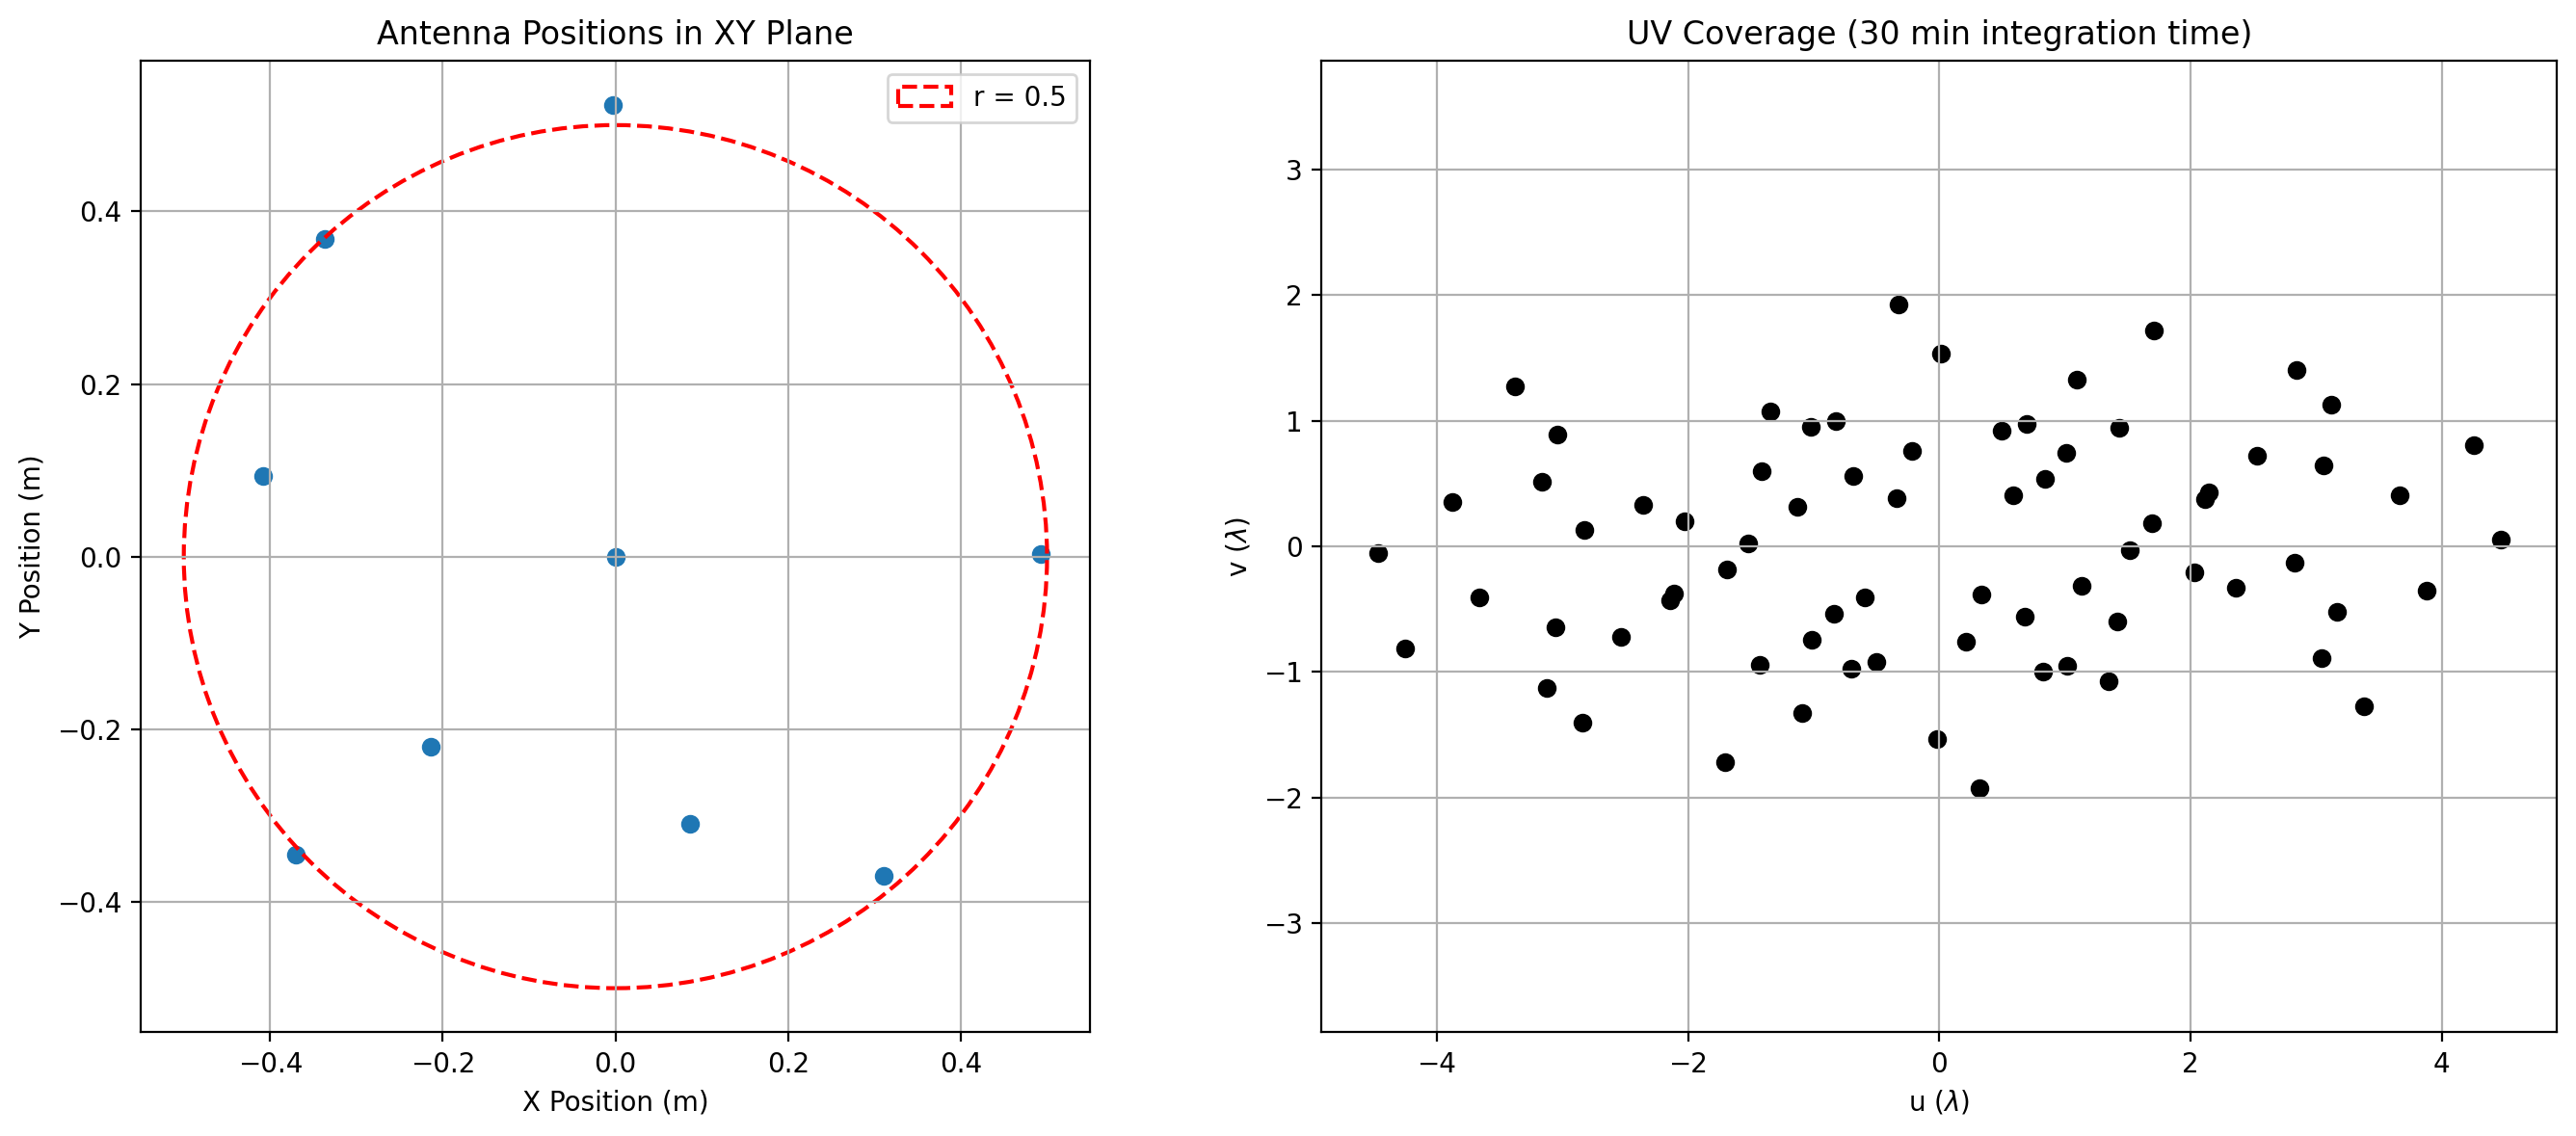

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Antenna configuration
ax[0].scatter(antenna_positions[:, 0].value, antenna_positions[:, 1].value)

ax[0].set_xlabel('X Position (m)')
ax[0].set_ylabel('Y Position (m)')
ax[0].set_title('Antenna Positions in XY Plane')
ax[0].grid()
ax[0].set_aspect('equal')

# Add red circle centered at (0,0), radius = 0.5 m
circle = Circle((0, 0), radius=0.5, edgecolor='red', facecolor='none', linewidth=1.5, linestyle='dashed', label = 'r = 0.5')
ax[0].add_patch(circle)
ax[0].legend()

# Plot individual baseline tracks
for i in range(num_antennas):
    for j in range(num_antennas):
        if i != j:
            ax[1].scatter(u_coords[:, i, j],v_coords[:, i, j],color='black')

ax[1].set_xlabel(r'u ($\lambda$)')
ax[1].set_ylabel(r'v ($\lambda$)')
ax[1].set_title(f'UV Coverage ({INT_TIME.to_value(u.min):.0f} min integration time)')
ax[1].grid()
ax[1].axis('equal')
plt.tight_layout()
plt.show()

# 2. Load the data

Set the folder

In [15]:
raw_data = [np.fromfile(file, dtype=np.complex64) for file in track(antenna_data_files, description="Loading data")]

/usr/lib/python3/dist-packages/rich/live.py:231: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

### 2.1 Visualize raw data

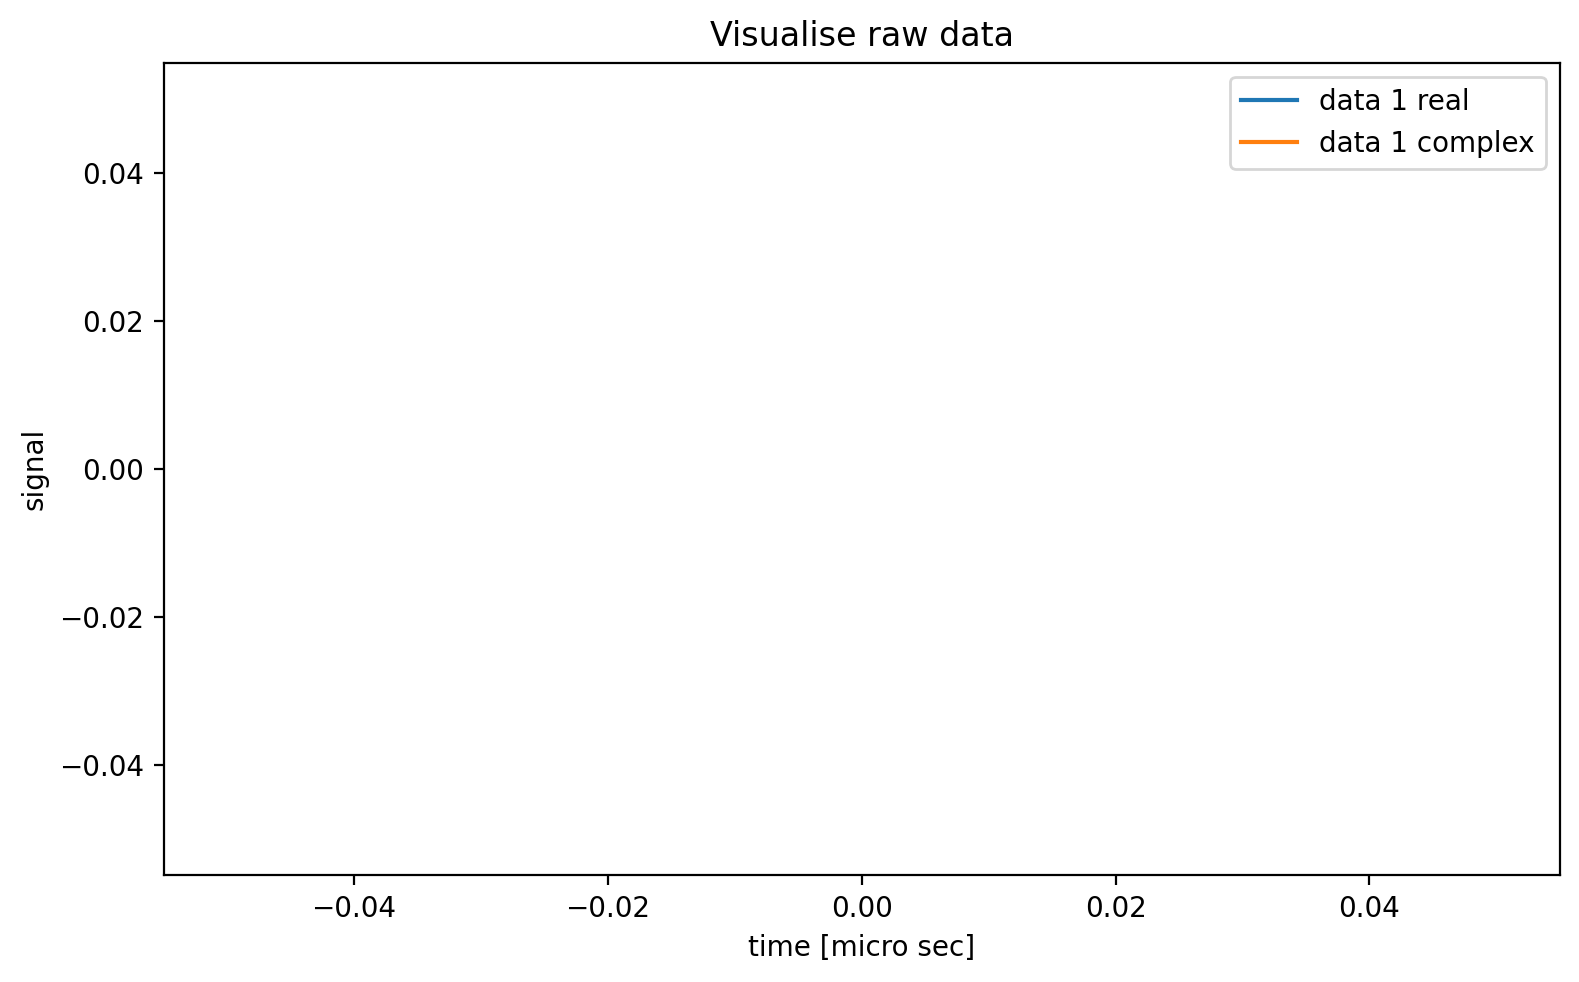

In [16]:
# visualise cut out of raw data
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('Visualise raw data')
n=0
for data in raw_data:
    n+=1
    ax.plot(np.real(data[0:100]), label = f'data {n} real')
    ax.plot(np.imag(data[0:100]), label = f'data {n} complex')

    
ax.set_xlabel("time [micro sec]")
ax.set_ylabel('signal')
ax.legend()
fig.tight_layout()
plt.show()

### 2.2 Truncate the data to uniformity

All data must have the same length

In [23]:
# Number of real observations and antennas
n_real_ant = len(raw_data)
n_obs = len(obs_times)

# Truncate data to the same length (compatible with n_channels) for all antennas
minlen = min(len(data) for data in raw_data)
nblocks = int((minlen // 10) // N_CHANNELS)  # divide minlen to reduce data size even further for saving resources during testing
truncation_index = int(nblocks * N_CHANNELS)
truncated_data = np.array([data[:truncation_index] for data in raw_data])
data_array = np.zeros((len(obs_times), num_antennas, truncation_index), dtype = complex)
data_array[:n_obs, :n_real_ant] = truncated_data.reshape(n_obs, n_real_ant, truncation_index)

### 2.4 simulate antenna's 

In [19]:
if SIMULATE_ANTENNAS:
    freq = np.sort(np.fft.fftfreq(N_CHANNELS, 1/(SAMP_RATE))) + CENTRAL_FREQ
    simfreqs = np.tile(freq, nblocks)
    for i in range(len(obs_times)):
        ra = radec_coords[i].ra.deg
        dec = radec_coords[i].dec.deg
        s = np.array([np.cos(dec)*np.cos(ra), np.cos(dec)*np.sin(ra), np.sin(dec)])
        for k in range(n_real_ant, num_antennas):
            b = antenna_positions[k]
            tau = np.dot(b, s)/c.c
            phase_shift = np.exp(-2j * np.pi * simfreqs * tau)
            data_array[i, k] = data_array[i, 0]*phase_shift

print(f"Data for {num_antennas} antennas extracted.")
print(f"{truncation_index} data points from each antenna.")


Data for 9 antennas extracted.
0 data points from each antenna.


### 2.5 Calculate FFT of the antennas

In [20]:
# FFT parameters
fs = SAMP_RATE.to_value(u.Hz) #frequency shift per data point

window = blackmanharris(N_CHANNELS)

fft_freqs = np.fft.fftshift(np.fft.fftfreq(N_CHANNELS, d=1/fs)) + CENTRAL_FREQ.to_value(u.Hz)

# Allocate FFT data
fft_data = np.zeros((N_OBS, num_antennas, nblocks, N_CHANNELS),dtype=np.complex64)

# calculate the power spectral density
power_spectra = np.zeros((len(obs_times), num_antennas, N_CHANNELS), dtype='complex64')

# Calculate FFTs
for k in track(range(N_OBS), description='Iterating through observations'):

    for i in range(num_antennas):

        # Get complete observation
        df = data_array[k, i, :]

        # Reshape into FFT blocks
        df_blocks = df.reshape(nblocks, N_CHANNELS)

        # Remove DC offset from each block
        df_blocks = df_blocks - np.mean(df_blocks, axis=1, keepdims=True)

        # Apply window to each block
        df_windowed = df_blocks * window[np.newaxis, :]

        # Calculate FFT along sample axis
        fft_output = np.fft.fft(df_windowed, axis=1)

        # Shift frequency axis
        fft_data[k, i] = np.fft.fftshift(fft_output, axes=1)

        frequency_welch, psd = welch(df, fs=SAMP_RATE, window=window, nperseg=N_CHANNELS, return_onesided=False)

        power_spectra[k, i] = np.fft.fftshift(psd)


ValueError: could not broadcast input array from shape (0,) into shape (2048,)

### 2.6 Visualise the FFT's

In [ ]:
# Plot FFT
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('FFT antenna signals')
for antenna in range(len(fft_data[0])):
    ax.plot(fft_freqs / 1e6, power_spectra[0, antenna], label=f'Antenna {antenna+1}')
ax.set_xlabel('Frequency [MHz]')
ax.set_ylabel('Power spectral density')
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

### 2.7 plot the shifted cross correlation to check for time delays

In [ ]:
# Select antennas and observation
# shoudln't do data driven here, it would be 9x9 can't see
ant1 = 0
ant2 = 1
obs = 0

# Get FFT blocks
spectrum1 = fft_data[obs, ant1]
spectrum2 = fft_data[obs, ant2]

# Calculate cross-spectrum for each block
block_cross_spectrum = spectrum1 * np.conj(spectrum2)

# Average over all FFT blocks
cross_spectrum = np.mean(block_cross_spectrum, axis=0)

# Undo frequency shift before inverse FFT
cross_spectrum = np.fft.ifftshift(cross_spectrum)

# Calculate cross-correlation
correlations = np.fft.ifft(cross_spectrum)

# Shift zero delay to centre
correlations = np.fft.fftshift(correlations)

# Calculate time delays
time_delays = (np.arange(N_CHANNELS) - N_CHANNELS // 2) / fs # what? are you sure?
print(time_delays*1.e9)

# Find maximum correlation
max_index = np.argmax(np.abs(correlations))

print('Maximum correlation:', correlations[max_index])
print('Time delay:', time_delays[max_index], 'seconds')
print('Sample shift:', max_index - N_CHANNELS // 2)

# Plot
fig, ax = plt.subplots(figsize=(8, 5))

ax.set_title(f'Cross-correlation antenna {ant1} and antenna {ant2}')

ax.plot(time_delays * 1e9, np.abs(correlations))

ax.set_xlabel('Time delay (ns)')
ax.set_ylabel('Cross-correlation magnitude')

ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

### 3 Compute ACM cube
calculate subband visibilities (cross-correlations) and add them to a data cube

In [ ]:
acm = np.zeros((len(obs_times), num_antennas, num_antennas), dtype='complex64')
for i in track(range(len(obs_times)), description='Iterating through observations'):
  obs_data = data_array[i]
  for ant1 in range(num_antennas):
    for ant2 in range(ant1, num_antennas):
      freq, cross_corr = csd(obs_data[ant1], obs_data[ant2], fs=SAMP_RATE, nperseg=N_CHANNELS, return_onesided=False)
      acm[i, ant1, ant2] = cross_corr[SUBBAND]

      if ant1 != ant2:
        acm[i, ant2, ant1] = np.conj(cross_corr[SUBBAND]) # property of frequency domain cross-correlation, saves time

print('ACM generated successfully!')

### 3.1 Define make_image function + helper function

In [ ]:
# Helper functions for generating images
def pixel_brightness(acm_single_pol, l, m, uv, frequency):
    a = acm_single_pol.astype(np.complex64)
    n = a.shape[0]
    uv_l = uv.astype(np.float32)
    uv_l = (uv_l * frequency/c.c).decompose()
    ll = l.to(u.rad).value
    mm = m.to(u.rad).value
    mask = np.ones((n, n), dtype=np.float32)
    mask -= np.diag(np.ones(n, dtype=np.float32)) # remove auto-correlations
    num_vis = mask.sum()
    brightness = (a*mask*np.exp(2j*np.pi*(uv_l[...,0]*ll + uv_l[...,1]*mm))).real.sum()
    return brightness/num_vis

def subband_frequency(subband_number, clock_frequency=SAMP_RATE):
    return (subband_number/N_CHANNELS)*clock_frequency + (CENTRAL_FREQ - clock_frequency/2)
    
def make_image(acm, num_pix, uv, frequency,
               l_range=(1.0, -1.0),
               m_range=(-1.0, 1.0)):

    img = np.zeros((num_pix, num_pix), dtype=np.float32)

    l_coor = np.linspace(*l_range, num_pix) * u.rad
    m_coor = np.linspace(*m_range, num_pix) * u.rad

    # Loop over image pixels
    for m_ix, m in enumerate(track(m_coor, description="Generating image")):

        for l_ix, l in enumerate(l_coor):

            # Calculate brightness for every FFT block
            brightness = 0

            for b in range(acm.shape[0]):

                brightness += pixel_brightness(acm[b], l, m, uv[b], frequency)

            # Average over the integration
            img[m_ix, l_ix] = brightness / acm.shape[0]

    pixel_sep = m_coor[1] - m_coor[0]
    half = pixel_sep.to_value(u.rad) / 2

    img_extent = (l_coor[0].value - half, l_coor[-1].value + half, m_coor[0].value - half, m_coor[-1].value + half)

    return img, img_extent

### 3.2 Make image of observation at chosen subband

In [ ]:
# Make and plot image

f = subband_frequency(SUBBAND)
fwhm =  ((c.c/f)/(largest_baseline)).decompose()*u.rad
num_pix = int(SKY_COVERAGE / (fwhm/2.5))
print(f"Number of pixels should be {num_pix}")

obs_num = 0 #??

#img, extent = make_image(acm[obs_num],num_pix,uv_blocks[obs_num],f)

img, extent = make_image(acm[obs_num, :, :], num_pix, uv[obs_num, :, :, :], f)

# Plot image
fig, ax = plt.subplots(figsize=(5, 5))

im = ax.imshow(np.abs(img), origin='lower', extent=extent)

ax.set_title(f"Simulated image at {f.to(u.MHz):.3f}")
ax.set_xlabel("pixel x")
ax.set_ylabel("pixel y")

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.show()


### 3.3 Make image of the PSF

In [ ]:
psf, psf_extent = make_image(np.ones_like(acm[obs_num, :, :]), num_pix, uv[obs_num, :, :, :], f)

# Plot image
fig, ax = plt.subplots(figsize=(5, 5))

im_psf = ax.imshow(psf, extent=psf_extent, origin='lower')

ax.set_title(f"Simulated PSF at {f.to(u.MHz):.3f}")
ax.set_xlabel("pixel x")
ax.set_ylabel("pixel y")

cbar = fig.colorbar(im_psf, ax=ax, fraction=0.046, pad=0.04)
plt.show()

# 4 Perform clean algorithm on simulated data

In [ ]:
def hdfig(subplots_def=None, scale=0.5, figsize=(8, 4.5)):
    """ Returns figure according to the LOFAR notebook"""
    fig = plt.figure(figsize=figsize, dpi=scale*1920/8)
    if subplots_def is None:
        return fig
    else:
        return fig, fig.subplots(*subplots_def)
    
def gaussian(height, center_x, center_y, width_x, width_y):
    """Returns a gaussian function with the given parameters"""
    width_x = float(width_x)
    width_y = float(width_y)
    return lambda x,y: height*np.exp(
                -(((center_x-x)/width_x)**2+((center_y-y)/width_y)**2)/2)

def moments(data):
    """Returns (height, x, y, width_x, width_y)
    the gaussian parameters of a 2D distribution by calculating its
    moments """
    total = data.sum()
    X, Y = np.indices(data.shape)
    x = (X*data).sum()/total
    y = (Y*data).sum()/total
    col = data[:, int(y)]
    width_x = np.sqrt(np.abs((np.arange(col.size)-x)**2*col).sum()/col.sum())
    row = data[int(x), :]
    width_y = np.sqrt(np.abs((np.arange(row.size)-y)**2*row).sum()/row.sum())
    height = data.max()
    return height, x, y, width_x, width_y

def fitgaussian(data):
    """Returns (height, x, y, width_x, width_y)
    the gaussian parameters of a 2D distribution found by a fit"""
    params = moments(data)
    errorfunction = lambda p: np.ravel(gaussian(*p)(*np.indices(data.shape)) -
                                 data)
    p, success = leastsq(errorfunction, params)
    return p

def subtraction(img_I, psf, gamma, model_image, max_strength_allowed, start_progress, num_pix):
    """Returns the image with subtracted psf, the new maxiumum value and the input model image with the found brightest point subtracted"""
# function to subract the psf centred around the brightest point in the image

    max_strength = max(img_I.reshape(num_pix**2)) # determine value of brightest pixel
    max_pos = np.where(img_I==max_strength)
    model_image[max_pos[0], max_pos[1]] += max_strength # add pixel brightness to model image

    percentage = (max_strength_allowed-max_strength)/start_progress # progress attempt
    if percentage*100 % 10 == 0:
        print(f"{percentage:.0%}")


    psf_sub = psf * max_strength * gamma # multiply dirty beam with max strength and gamma factor
    shift_psf = ndimage.shift(psf_sub, (-((num_pix//2)-max_pos[0]), -((num_pix//2)-max_pos[1]))) # shift psf centre to brightest pixel

    new_image = img_I-shift_psf # remove psf from image
    
    max_strength = max(new_image.reshape(num_pix**2)) # calculate new maximum
    return {
        "new_pic" : new_image,
        "max_value" : max_strength,
        "model_image" : model_image,

    }


### 4.1 Loop over image until max pixel value is reached

In [ ]:
max_strength = max(img.reshape(num_pix**2)) # starting maximum value of the image
max_allowed = 0.5*1e-7 # set this to the maximum you want the cleaner to go to 
new_image = img.copy()
model_image = np.zeros_like(img)
start = max_allowed-max_strength

gamma = 0.5 # set this to the needed gamma parameter for cleaning

while max_strength>max_allowed: # cleaning loop runs until the brightest point in the image is less bright than the set max_allowed
    info = subtraction(new_image, psf, gamma, model_image, max_allowed, start, num_pix)
    new_image = info["new_pic"] 
    max_strength = info["max_value"]
    model_image = info["model_image"]

### 4.2 Convolve the image

In [ ]:
params = fitgaussian(psf)
fit = gaussian(*params)
clean_beam = fit(*np.indices(psf.shape))

convolved_image = fftconvolve(model_image, clean_beam, mode = "same")

fig, (ax_xx, ax_yy) = hdfig((1,2), figsize=(10,6))
mp_xx = ax_xx.imshow(convolved_image)
ax_xx.set_title("convolved")
mp_yy = ax_yy.imshow(img)
ax_yy.set_title("original")

fig.colorbar(mp_xx, ax=ax_xx)
fig.colorbar(mp_yy, ax=ax_yy)

# 5 Simulate time delays

In [ ]:
def add_delay_errors(acm, frequency, delay_rms_ns, seed=None):
    freq = frequency.to(u.Hz)
    
    n_ant = acm.shape[0]

    # Independent delay error for each antenna (seconds)
    delays = np.random.normal(0, delay_rms_ns *1e-9, n_ant)

    # Delay difference for each antenna pair
    delay_matrix = delays[None, :] - delays[:, None]

    # Convert delay errors to phase errors
    phase_errors = 2 * np.pi * freq * delay_matrix

    # Apply phase errors to the visibility matrix
    acm_corrupted = acm * np.exp(1j * phase_errors.value)

    return acm_corrupted, delays

### 5.1 Visualise time delays

In [ ]:
delay_errors = [0, 0.1, 0.5, 1, 2, 5]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, delay_ns in zip(axes.flat, delay_errors):

    acm_test, delays = add_delay_errors(acm, f, delay_ns)

    img, extent = make_image(acm_test, num_pix, uv, f)

    im = ax.imshow(img, origin="lower", extent=extent)

    ax.set_title(f"Delay RMS = {delay_ns} ns")
    ax.set_xlabel("l [rad]")
    ax.set_ylabel("m [rad]")

    fig.colorbar(im, ax=ax)

plt.show()
